# 9. Invalid-intent rejection (Figure 6 of the Intent Engine paper)

**Request (quoted from the researcher).**
> Now I want to perform the experiment related to Figure-6 from Intent Engine Paper.
> Model: Qwen 4B & 9B. Settings: zero-shot, few-shot, enable/disable thinking.
> Write the experimental policy and findings in "9.invalidIntentRejection.ipynb".

**What Figure 6 is.** The paper gives its baselines the 195 *invalid* intents (ambiguous, conflicting, malformed, unsupported) and asks how often each method returns no SLO. A good system should reject these. A bad one invents constraints (a false accept).

## 1. Experimental policy

| Item | Choice | Why |
|---|---|---|
| Data | the 195 invalid records (`meta.status != valid`): ambiguous 65, conflicting 49, malformed 35, unsupported 46 (real 55 / synthetic 140) | Same set as Fig 6 of the paper. The 521 valid records are not used here |
| Models | Qwen3.5-4B and Qwen3.5-9B | as requested |
| Conditions (4 per model) | zero-shot (`zs_cot_p_mc_system.txt` + `zs_p_paper_user.txt`), few-shot (`fs2_unitFixed+6_prompt.txt`), each with thinking off and on | the same prompts and settings as the valid-record runs, so results are directly comparable |
| Prompt changes | **none** | Neither prompt tells the model to reject. This is the paper's baseline situation: the model is never told what to do with a bad intent. We do not add a reject instruction here. That would be a separate experiment |
| Decoding | greedy (temperature 0, top_p 1, seed 0), bf16, vLLM, batch 64; zero-shot max 2,048 tokens; thinking = 4,096 thinking + 1,024 answer tokens with budget forcing (as in notebooks 4 and 6) | unchanged |
| Snapshot | the same single snapshot is given in the prompt | unchanged |
| Run dirs | `outputs/runs/*_invalid_*` (runner option `--subset invalid --tag invalid`; chain script `scripts/run_invalid_chain.sh`) | each keeps raw text, parsed JSON and thinking text |

**Outcome of one response** (`src/reject.py`):
- **rejected**: JSON parsed, `slos` is an empty list.
- **unparseable**: no JSON object with a `slos` list could be extracted (for example truncated output). No SLO reaches the orchestrator, so the paper-style rate counts it as a rejection. We show it separately.
- **accepted** (false accept): at least one SLO returned.

**Rejection rate (paper Eq. 8):** for category c, `(rejected + unparseable) / N_c`. The *strict* rate counts only `rejected`. Both are reported.

**What is different from the paper.** The paper used GPT-4.1 mini and also ran zero-shot CoT and few-shot CoT. We run no CoT. Our few-shot prompt (fs-f2) is our own, not the paper's (the paper shows only 3 of its 6 examples), and it has no example of a rejection. The paper's numbers below are read from its bar chart (about plus or minus 0.03) and from the text. They are a loose reference, not a reproduction target.

In [1]:
import glob, json, sys
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.reject import rejection_rows, rejection_rates, CATEGORIES

MODELS = {"Qwen3.5-4B": "qwen35-4b", "Qwen3.5-9B": "qwen35-9b"}
CONDS = {  # label -> run-dir prefix
    "zero-shot": "zs_p_mc_invalid_",
    "zero-shot + thinking": "zs_think_p_mc_invalid_",
    "few-shot": "fs-f2_invalid_",
    "few-shot + thinking": "fs-f2_think_invalid_",
}
runs = {}
for m, tag in MODELS.items():
    for c, pre in CONDS.items():
        d = sorted(glob.glob(str(ROOT / "outputs/runs" / f"{pre}{tag}_2*")))
        assert len(d) == 1, (m, c, d)
        runs[(m, c)] = d[0]
rows = {k: rejection_rows(v) for k, v in runs.items()}
rates = {k: rejection_rates(v) for k, v in rows.items()}
print({k: len(v) for k, v in rows.items()})

{('Qwen3.5-4B', 'zero-shot'): 195, ('Qwen3.5-4B', 'zero-shot + thinking'): 195, ('Qwen3.5-4B', 'few-shot'): 195, ('Qwen3.5-4B', 'few-shot + thinking'): 195, ('Qwen3.5-9B', 'zero-shot'): 195, ('Qwen3.5-9B', 'zero-shot + thinking'): 195, ('Qwen3.5-9B', 'few-shot'): 195, ('Qwen3.5-9B', 'few-shot + thinking'): 195}


## 2. Results

### 2.1 Rejection rate per category (paper-style: rejected + unparseable)

In [2]:
tab = pd.DataFrame({k: {c: rates[k][c]["rate"] for c in CATEGORIES + ["overall"]} for k in rates}).T
tab.index.names = ["model", "condition"]
tab.round(3)

ambiguous  conflicting  malformed  \
model      condition                                                 
Qwen3.5-4B zero-shot                 0.585         0.00      0.114   
           zero-shot + thinking      0.938         0.00      0.114   
           few-shot                  0.108         0.00      0.343   
           few-shot + thinking       0.969         0.00      0.257   
Qwen3.5-9B zero-shot                 0.062         0.00      0.000   
           zero-shot + thinking      0.785         0.02      0.229   
           few-shot                  0.323         0.02      0.429   
           few-shot + thinking       1.000         0.00      0.257   

                                 unsupported  overall  
model      condition                                   
Qwen3.5-4B zero-shot                   0.196    0.262  
           zero-shot + thinking        0.826    0.528  
           few-shot                    0.370    0.185  
           few-shot + thinking         0.978    0.600  
Qwen3.5-9B zero-shot                   0.087    0.041  
           zero-shot + thinking        0.935    0.528  
           few-shot                    0.348    0.272  
           few-shot + thinking         1.000    0.615

### 2.2 Counts behind the rates (rejected / unparseable / accepted)

In [3]:
cnt = pd.DataFrame({k: {c: f'{rates[k][c]["rejected"]}/{rates[k][c]["unparseable"]}/{rates[k][c]["accepted"]}' for c in CATEGORIES + ["overall"]} for k in rates}).T
cnt.index.names = ["model", "condition"]
cnt

ambiguous conflicting malformed unsupported  \
model      condition                                                          
Qwen3.5-4B zero-shot              38/0/27      0/0/49    4/0/31      9/0/37   
           zero-shot + thinking    61/0/4      0/0/49    4/0/31      38/0/8   
           few-shot                7/0/58      0/0/49   12/0/23     17/0/29   
           few-shot + thinking     63/0/2      0/0/49    9/0/26      45/0/1   
Qwen3.5-9B zero-shot               4/0/61      0/0/49    0/0/35      4/0/42   
           zero-shot + thinking   51/0/14      1/0/48    8/0/27      43/0/3   
           few-shot               21/0/44      1/0/48   15/0/20     16/0/30   
           few-shot + thinking     65/0/0      0/0/49    9/0/26      46/0/0   

                                  overall  
model      condition                       
Qwen3.5-4B zero-shot             51/0/144  
           zero-shot + thinking  103/0/92  
           few-shot              36/0/159  
           few-shot + thinking   117/0/78  
Qwen3.5-9B zero-shot              8/0/187  
           zero-shot + thinking  103/0/92  
           few-shot              53/0/142  
           few-shot + thinking   120/0/75

### 2.3 Figure 6 equivalent

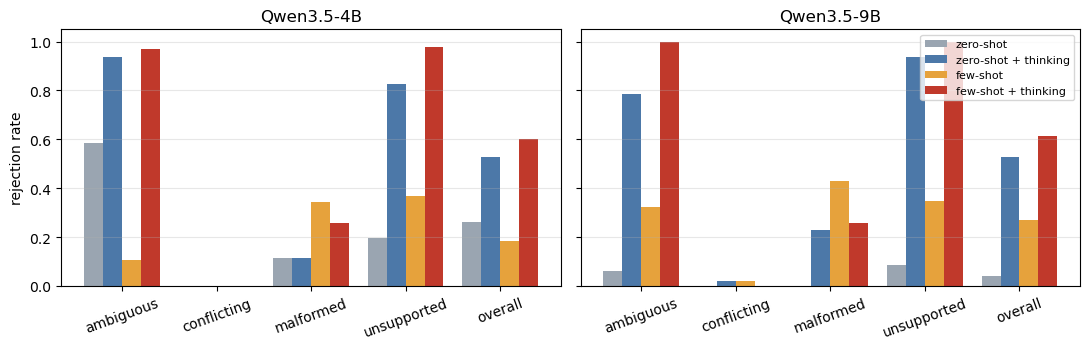

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
cols = ["#9aa5b1", "#4c78a8", "#e6a23c", "#c0392b"]
x = np.arange(len(CATEGORIES) + 1)
for ax, m in zip(axes, MODELS):
    for i, c in enumerate(CONDS):
        ax.bar(x + (i - 1.5) * 0.2, [rates[(m, c)][k]["rate"] for k in CATEGORIES + ["overall"]], 0.2, label=c, color=cols[i])
    ax.set_xticks(x); ax.set_xticklabels(CATEGORIES + ["overall"], rotation=20)
    ax.set_title(m); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=.3)
axes[0].set_ylabel("rejection rate"); axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

### 2.4 Strict rate (empty `slos` only) and how many responses were unparseable

In [5]:
s = pd.DataFrame({k: {"strict overall": rates[k]["overall"]["strict_rate"], "unparseable": rates[k]["overall"]["unparseable"],
                      "truncated": sum(r["truncated"] for r in rows[k])} for k in rates}).T
s.index.names = ["model", "condition"]; s.round(3)

strict overall  unparseable  truncated
model      condition                                                   
Qwen3.5-4B zero-shot                      0.262          0.0        0.0
           zero-shot + thinking           0.528          0.0        0.0
           few-shot                       0.185          0.0        0.0
           few-shot + thinking            0.600          0.0        0.0
Qwen3.5-9B zero-shot                      0.041          0.0        0.0
           zero-shot + thinking           0.528          0.0        0.0
           few-shot                       0.272          0.0        0.0
           few-shot + thinking            0.615          0.0        0.0

### 2.5 Reference: paper, GPT-4.1 mini (chart readings, about plus or minus 0.03)

In [6]:
paper = pd.DataFrame({
    "ambiguous":   {"zero-shot": .98, "few-shot": .62, "zero-shot CoT": 1.0, "few-shot CoT": .82, "Intent Engine": 1.0},
    "conflicting": {"zero-shot": .90, "few-shot": 0.0, "zero-shot CoT": .88, "few-shot CoT": 0.0, "Intent Engine": .94},
    "malformed":   {"zero-shot": .69, "few-shot": .09, "zero-shot CoT": .75, "few-shot CoT": .17, "Intent Engine": 1.0},
    "unsupported": {"zero-shot": .98, "few-shot": .91, "zero-shot CoT": .98, "few-shot CoT": .87, "Intent Engine": 1.0}})
paper

,ambiguous,conflicting,malformed,unsupported
zero-shot,0.98,0.90,0.69,0.98
few-shot,0.62,0.00,0.09,0.91
zero-shot CoT,1.00,0.88,0.75,0.98
few-shot CoT,0.82,0.00,0.17,0.87
Intent Engine,1.00,0.94,1.00,1.00


### 2.6 By source and by level (accepted share = false-accept rate)

In [7]:
df = pd.concat([pd.DataFrame(v).assign(model=k[0], cond=k[1]) for k, v in rows.items()])
df["false_accept"] = df.outcome.eq("accepted")
print(df.groupby(["model", "cond", "source"]).false_accept.mean().unstack().round(3))
print(df.groupby(["model", "cond", "level"]).false_accept.mean().unstack().round(3))

source                            real  synthetic
model      cond                                  
Qwen3.5-4B few-shot              0.873      0.793
           few-shot + thinking   0.382      0.407
           zero-shot             0.745      0.736
           zero-shot + thinking  0.455      0.479
Qwen3.5-9B few-shot              0.891      0.664
           few-shot + thinking   0.364      0.393
           zero-shot             1.000      0.943
           zero-shot + thinking  0.509      0.457
level                                1      2      3      4      5
model      cond                                                   
Qwen3.5-4B few-shot              0.942  0.818  0.778  0.889  0.517
           few-shot + thinking   0.462  0.636  0.139  0.378  0.379
           zero-shot             0.750  0.879  0.722  0.667  0.690
           zero-shot + thinking  0.577  0.727  0.167  0.422  0.448
Qwen3.5-9B few-shot              0.827  0.758  0.722  0.689  0.586
           few-shot + thinking 

### 2.7 What the models return for invalid intents

In [8]:
acc = df[df.outcome == "accepted"]
print("SLOs per false-accepted response (mean):")
print(acc.groupby(["model", "cond"]).n_slos.mean().round(2))
print()
print("completion tokens, median:")
print(df.groupby(["model", "cond"]).completion_tokens.median())

SLOs per false-accepted response (mean):
model       cond                
Qwen3.5-4B  few-shot                1.65
            few-shot + thinking     1.71
            zero-shot               1.61
            zero-shot + thinking    1.68
Qwen3.5-9B  few-shot                2.45
            few-shot + thinking     1.76
            zero-shot               1.58
            zero-shot + thinking    1.89
Name: n_slos, dtype: float64

completion tokens, median:
model       cond                
Qwen3.5-4B  few-shot                  89.0
            few-shot + thinking     4123.0
            zero-shot                 85.0
            zero-shot + thinking    4121.0
Qwen3.5-9B  few-shot                 156.0
            few-shot + thinking     4123.0
            zero-shot                 88.0
            zero-shot + thinking    4120.0
Name: completion_tokens, dtype: float64


In [9]:
from src.data_io import load_records
recs = {r["index"]: r for r in load_records()}
def show(model, cond, cat, k=3):
    d = df[(df.model == model) & (df.cond == cond) & (df.category == cat) & (df.outcome == "accepted")].head(k)
    preds = {json.loads(l)["index"]: json.loads(l) for l in open(runs[(model, cond)] + "/predictions.jsonl")}
    for i in d["index"]:
        e = recs[i]["input"]["intent"]["expression"].replace("descartesresearch/", "")
        out = [(s.get("metric") or s.get("type"), s["target"].get("cmp"), s["target"].get("op"), s["target"].get("value")) for s in preds[i]["parsed"]["slos"]]
        print(f"[{cat}] {e}\n   -> {out}\n")
for cat in ["conflicting", "malformed", "ambiguous"]:
    show("Qwen3.5-9B", "few-shot", cat, 2)

[conflicting] Please place teastore-auth on the node with the highest CPU capacity and the lowest CPU capacity at once.
   -> [('cpu_capacity', '>=', 'highest', 4000), ('cpu_capacity', '<=', 'lowest', 2000)]

[conflicting] Place teastore-auth only on the cloud and only on the edge simultaneously.
   -> [('placement_location', None, 'set', 'cloud'), ('placement_location', None, 'set', 'edge')]

[malformed] teastore-recommender below memory 50 and port maybe not sure ...
   -> [('memory_utilization', '<=', None, 50), ('port_utilization', '<=', None, 0.050862630208333336)]

[malformed] teastore-auth cloud node best storage broken sentence and
   -> [('placement_location', None, 'set', 'cloud'), ('storage_utilization', '<=', 'highest', 57.0)]

[ambiguous] Please deploy teastore-db somewhere sensible, with enough headroom and generally good performance.
   -> [('placement_location', None, 'set', 'any')]

[ambiguous] I need teastore-image deployed somewhere reasonable, with enough room and d

### 2.8 Thinking budget on invalid intents

In [10]:
rows_f = []
for (m, c), d in runs.items():
    if "thinking" not in c:
        continue
    preds = [json.loads(l) for l in open(d + "/predictions.jsonl")]
    from src.reject import outcome
    for forced in (True, False):
        sub = [p for p in preds if bool(p.get("forced_close")) == forced]
        rows_f.append({"model": m, "cond": c, "thought": "cut by budget" if forced else "finished", "n": len(sub),
                       "rejected": round(sum(outcome(p) == "rejected" for p in sub) / max(1, len(sub)), 2)})
pd.DataFrame(rows_f).pivot_table(index=["model", "cond"], columns="thought", values=["n", "rejected"])

n               rejected         
thought                         cut by budget finished cut by budget finished
model      cond                                                              
Qwen3.5-4B few-shot + thinking          177.0     18.0          0.63     0.33
           zero-shot + thinking         157.0     38.0          0.48     0.74
Qwen3.5-9B few-shot + thinking          177.0     18.0          0.63     0.44
           zero-shot + thinking         104.0     91.0          0.54     0.52

## 3. Comparison with Figure 6 of the paper

The paper reports rejection rates for GPT-4.1 mini (Fig 6 and the text). We compare them with our two Qwen models, setting by setting.

**Matching of settings (approximate).**

| Paper (GPT-4.1 mini) | Ours (Qwen3.5) | How close |
|---|---|---|
| zero-shot | zero-shot (millicores prompt) | same idea, one word changed in the prompt (cores to millicores) |
| few-shot | few-shot (fs-f2) | **different prompt**: the paper's has 3 visible examples plus 3 hidden ones, ours has 6 of our own |
| zero-shot CoT | zero-shot + thinking | **not the same**: the paper adds the phrase "Let's think step-by-step"; we switch on the model's native thinking mode |
| few-shot CoT | few-shot + thinking | same remark |
| Intent Engine | none | we do not implement it; shown only as a reference |

**Caveats on the paper's numbers.** They are chart readings (about plus or minus 0.03), except the values stated in the text (Intent Engine overall 98.5%, conflicting 93.9%). The paper does not list the counts per category, so we use the dataset counts (65 / 49 / 35 / 46) to compute an approximate overall rate from the chart readings. Different model, different prompt wording: this is a comparison of direction and size, not a reproduction.

In [11]:
PAIRS = {"zero-shot": "zero-shot", "few-shot": "few-shot", "zero-shot + thinking": "zero-shot CoT", "few-shot + thinking": "few-shot CoT"}
N = {"ambiguous": 65, "conflicting": 49, "malformed": 35, "unsupported": 46}
w = pd.Series(N) / sum(N.values())
paper["overall (approx.)"] = (paper[CATEGORIES] * w).sum(axis=1)
ours = pd.DataFrame({k: {c: rates[k][c]["rate"] for c in CATEGORIES + ["overall"]} for k in rates}).T
ours = ours.rename(columns={"overall": "overall (approx.)"})
rows_c = []
for m in MODELS:
    for c, pc in PAIRS.items():
        o, pr = ours.loc[(m, c)], paper.loc[pc]
        rows_c.append({"model": m, "our setting": c, "paper setting": pc, **{f"{k}: ours / paper / diff": f"{o[k]:.2f} / {pr[k]:.2f} / {o[k]-pr[k]:+.2f}" for k in CATEGORIES + ["overall (approx.)"]}})
cmp_df = pd.DataFrame(rows_c).set_index(["model", "our setting", "paper setting"])
pd.set_option("display.max_colwidth", None, "display.width", 250)
cmp_df

ambiguous: ours / paper / diff conflicting: ours / paper / diff malformed: ours / paper / diff unsupported: ours / paper / diff overall (approx.): ours / paper / diff
model      our setting          paper setting                                                                                                                                                                       
Qwen3.5-4B zero-shot            zero-shot                0.58 / 0.98 / -0.40              0.00 / 0.90 / -0.90            0.11 / 0.69 / -0.58              0.20 / 0.98 / -0.78                    0.26 / 0.91 / -0.65
           few-shot             few-shot                 0.11 / 0.62 / -0.51              0.00 / 0.00 / +0.00            0.34 / 0.09 / +0.25              0.37 / 0.91 / -0.54                    0.18 / 0.44 / -0.25
           zero-shot + thinking zero-shot CoT            0.94 / 1.00 / -0.06              0.00 / 0.88 / -0.88            0.11 / 0.75 / -0.64              0.83 / 0.98 / -0.15                    0.53 / 0.92 / -0.39
           few-shot + thinking  few-shot CoT             0.97 / 0.82 / +0.15              0.00 / 0.00 / +0.00            0.26 / 0.17 / +0.09              0.98 / 0.87 / +0.11                    0.60 / 0.51 / +0.09
Qwen3.5-9B zero-shot            zero-shot                0.06 / 0.98 / -0.92              0.00 / 0.90 / -0.90            0.00 / 0.69 / -0.69              0.09 / 0.98 / -0.89                    0.04 / 0.91 / -0.87
           few-shot             few-shot                 0.32 / 0.62 / -0.30              0.02 / 0.00 / +0.02            0.43 / 0.09 / +0.34              0.35 / 0.91 / -0.56                    0.27 / 0.44 / -0.17
           zero-shot + thinking zero-shot CoT            0.78 / 1.00 / -0.22              0.02 / 0.88 / -0.86            0.23 / 0.75 / -0.52              0.93 / 0.98 / -0.05                    0.53 / 0.92 / -0.39
           few-shot + thinking  few-shot CoT             1.00 / 0.82 / +0.18              0.00 / 0.00 / +0.00            0.26 / 0.17 / +0.09              1.00 / 0.87 / +0.13                    0.62 / 0.51 / +0.11

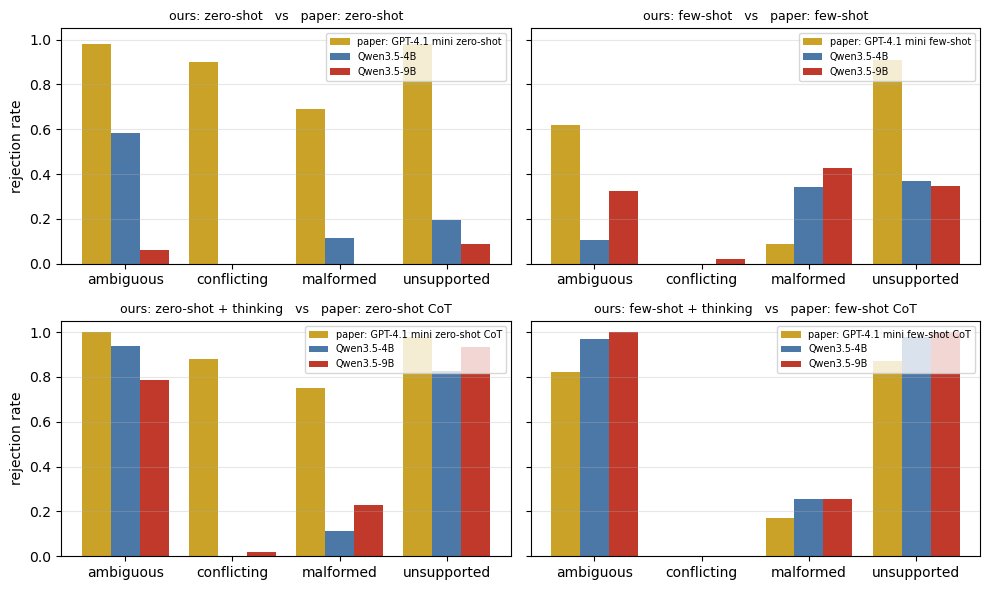

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharey=True)
x = np.arange(len(CATEGORIES))
for ax, (c, pc) in zip(axes.ravel(), PAIRS.items()):
    ax.bar(x - 0.27, [paper.loc[pc][k] for k in CATEGORIES], 0.27, color="#c9a227", label=f"paper: GPT-4.1 mini {pc}")
    ax.bar(x, [ours.loc[("Qwen3.5-4B", c)][k] for k in CATEGORIES], 0.27, color="#4c78a8", label="Qwen3.5-4B")
    ax.bar(x + 0.27, [ours.loc[("Qwen3.5-9B", c)][k] for k in CATEGORIES], 0.27, color="#c0392b", label="Qwen3.5-9B")
    ax.set_xticks(x); ax.set_xticklabels(CATEGORIES); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=.3)
    ax.set_title(f"ours: {c}   vs   paper: {pc}", fontsize=9); ax.legend(fontsize=7, loc="upper right")
axes[0, 0].set_ylabel("rejection rate"); axes[1, 0].set_ylabel("rejection rate")
plt.tight_layout(); plt.show()

In [13]:
# Intent Engine reference (paper) next to our best Qwen setting per category
best = ours[CATEGORIES].max()
ref = pd.DataFrame({"paper: Intent Engine": paper.loc["Intent Engine"][CATEGORIES], "paper: best baseline": paper.drop("Intent Engine")[CATEGORIES].max(),
                    "ours: best Qwen setting": best})
ref["gap to Intent Engine"] = ref["ours: best Qwen setting"] - ref["paper: Intent Engine"]
ref.round(2)

,paper: Intent Engine,paper: best baseline,ours: best Qwen setting,gap to Intent Engine
ambiguous,1.00,1.00,1.00,0.00
conflicting,0.94,0.90,0.02,-0.92
malformed,1.00,0.75,0.43,-0.57
unsupported,1.00,0.98,1.00,0.00


### 3.1 Reading of the comparison

Differences are our rate minus the paper's (GPT-4.1 mini). All paper values are chart readings.

1. **Zero-shot: the paper's model rejects, ours do not.** GPT-4.1 mini rejects 0.98 of ambiguous, 0.90 of conflicting, 0.69 of malformed and 0.98 of unsupported intents with no help. Qwen 4B is 0.40 to 0.90 lower in every category (for example ambiguous 0.58, conflicting 0.00). Qwen 9B is lower still (overall 0.04 against about 0.91 for the paper). So the rejection behaviour of the large hosted model does not appear in these small models. The 9B is even less willing to reject than the 4B in zero-shot (ambiguous 0.06 against 0.58).

2. **Few-shot: the paper's drop is not the same as ours.** In the paper, few-shot prompting collapses rejection of conflicting (0.00) and malformed (0.09) intents and lowers ambiguous to 0.62. In ours, conflicting is also about 0.00, but malformed is *higher* than the paper (0.34 and 0.43 against 0.09). Ambiguous is lower than the paper for the 4B (0.11 against 0.62) and for the 9B (0.32). Unsupported is much lower than the paper (about 0.35 against 0.91). The paper's own hidden examples and our six examples differ, so we cannot tell which part of this comes from the prompt and which from the model.

3. **Thinking closes much of the gap for ambiguous and unsupported intents.** Zero-shot with thinking reaches 0.94 and 0.78 for ambiguous intents (paper's zero-shot CoT: 1.00) and 0.83 and 0.93 for unsupported intents (paper: 0.98). Few-shot with thinking is *above* the paper's few-shot CoT for ambiguous (0.97 and 1.00 against 0.82) and unsupported (0.98 and 1.00 against 0.87). The overall rate is 0.60 and 0.62 against about 0.51 for the paper's few-shot CoT (approximate). Caution: our thinking mode is not the same as the paper's CoT phrase, so this is not a like-for-like test of CoT.

4. **Conflicting intents are the clearest gap.** The paper's zero-shot and zero-shot CoT reject 0.90 and 0.88 of conflicting intents. We reach at most 0.02 in any setting, including the settings with thinking. GPT-4.1 mini seems to see the contradiction when it reads the whole request, and our models translate each phrase on its own. This is the single largest difference between the paper's baselines and ours.

5. **Malformed intents stay below the paper's best baseline.** The paper's best baseline (zero-shot CoT) reaches 0.75. Our best Qwen setting reaches 0.43. The Intent Engine reaches 1.00 with its validation step.

6. **Against the full Intent Engine.** The Intent Engine rejects ambiguous and unsupported intents at 1.00, conflicting at 0.94 and malformed at 1.00 (the last table above). Our best Qwen setting matches it for ambiguous and unsupported (1.00, with thinking), but is 0.92 below for conflicting and 0.57 below for malformed. These two categories need a check that the model alone does not do. This supports the idea that a validation step (as in the paper's Algorithm 1) matters for rejection, not only for translation.

7. **What we can and cannot say.** The pattern across categories is clear, because the gaps are large (0.4 to 0.9). Small gaps (for example +0.09 overall for few-shot with thinking) should not be read as real: the paper's numbers are chart readings, the models and prompts differ, and ours are single greedy runs. The paper's overall rate is approximate, because we weight chart readings by the dataset counts.

## 4. Findings

**How to read the numbers.** The rate is the share of the invalid intents for which the model returned no SLO (Section 2.1). Higher is better. Counts per category: ambiguous 65, conflicting 49, malformed 35, unsupported 46. All numbers are single greedy runs, so small differences should not be read as real.

1. **Without thinking, the models almost never reject.** Overall rejection is 0.04 to 0.27. The 9B zero-shot run rejects 8 of 195 intents. When a model answers an invalid intent, it returns about 1.6 SLOs on average (2.45 for the 9B with few-shot). So the model invents constraints. The paper's GPT-4.1 mini rejects 98% of ambiguous and unsupported intents in zero-shot (chart reading, Section 2.5). Our small models do far worse with the same kind of prompt. A hosted large model seems to refuse on its own, and the small ones do not.

2. **Few-shot examples do not help in a consistent way.** The overall rate goes down for the 4B (0.26 to 0.18) and up for the 9B (0.04 to 0.27). For the 4B the ambiguous rate drops from 0.58 to 0.11. Our six examples always end in a non-empty answer, so they may teach the model to always answer. This is the same effect that the paper reports for its few-shot prompt (its conflicting and malformed rates fall to about zero).

3. **Thinking helps a lot, and it helps both sizes about equally.** With thinking the overall rate is 0.53 to 0.62 for both models, and the 4B and the 9B are within 0.015 of each other. Ambiguous intents reach 0.78 to 1.00 and unsupported intents 0.83 to 1.00. The model notices that no number is given, or that a metric (for example carbon footprint) does not exist. This is a place where thinking pays off for every size, unlike the valid intents, where it helped only the small models.

4. **Conflicting intents are almost never rejected.** The rate is 0.00 to 0.02 in all eight settings. The model returns both halves of the conflict, for example `highest` and `lowest` CPU capacity together, or placement on the cloud and on the edge together (Section 2.7). The paper's GPT-4.1 mini rejects about 90% of them in zero-shot, and the full Intent Engine rejects 94% because its validation algorithm checks the SLOs against each other. A model that translates each phrase on its own does not do this check.

5. **Malformed intents are also hard** (0.00 to 0.43). The best run is the 9B with few-shot and no thinking (0.43). Thinking does not help here (0.11 to 0.26). The models take the readable part and add the rest. For ``below memory 50 and port maybe not sure'' they write a memory threshold of 50 and a port-utilization value that they take from the snapshot.

6. **Ambiguous intents are answered with a guess.** For ``somewhere sensible, with enough headroom and good performance'', the model often returns `placement = any`, or it turns ``good performance'' into several lowest and highest values from the snapshot. These SLOs look valid and would be passed to a scheduler. This is the hallucination risk that the project proposal describes.

7. **No clear pattern by source or level.** The false-accept rates for real and synthetic intents and for levels 1 to 5 move in both directions between runs (Section 2.6). We did not test this further.

8. **Cost and the thinking budget.** Thinking took a median of about 4,120 tokens per invalid intent, against 85 to 156 without it. The thought was cut by the 4,096-token budget in 104 to 177 of the 195 intents (Section 2.8). The rejection rate of cut and finished thoughts differs in both directions, so we cannot say what a longer budget would do.

**What this means for the next steps.** The prompts used here never mention rejection. The results show where help is needed: (a) a short instruction and examples that say when to return an empty list, (b) a consistency check between SLOs for conflicting requests, as in the paper's Algorithm 1, and (c) thinking, which gives the largest gain for ambiguous and unsupported intents. These are the ideas for the ambiguity experiments of the final report.

**Caveats.** Single greedy runs, no confidence intervals. The paper's values are chart readings (about plus or minus 0.03) for a different model and prompt, so they show direction, not a reproduction target. We count a response as accepted when it returns any SLO, even if part of it is reasonable. All 8 x 195 responses were parseable, so the strict and the paper-style rates are the same. Our few-shot prompt was designed for valid intents and has no example of a refusal. The results are for the two Qwen models only.